<a href="https://colab.research.google.com/github/rodrigodacunhaconceicao/parking-garage-occupancy-original/blob/main/MultivariateProjectv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [126]:
#Necessary Installs
!pip install -q factor_analyzer "pingouin==0.5.5"

In [218]:
#Necessary Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator
from factor_analyzer import FactorAnalyzer
import pingouin as pg
from numpy.linalg import inv
from sklearn.impute import KNNImputer #new
from pandas.core.arrays import numeric #new
import seaborn as sns #new


In [261]:
#Import data

df1 = pd.read_excel("dataset_18_24.xlt", na_values = [":", "#N/A"])
df2 = pd.read_excel("dataset_25_49.xlt", na_values = [":", "#N/A"])
df3 = pd.read_excel("dataset_50_65.xlt", na_values = [":", "#N/A"])
df4 = pd.read_excel("dataset_65plus.xlt", na_values = [":", "#N/A"])

ue_countries = [
    "Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus",
    "Czechia", "Denmark", "Estonia", "Finland", "France",
    "Germany", "Greece", "Hungary", "Ireland", "Italy",
    "Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands",
    "Poland", "Portugal", "Romania", "Slovakia", "Slovenia",
    "Spain", "Sweden"
]

df1 = df1[df1["Country"].isin(ue_countries)]
df2 = df2[df2["Country"].isin(ue_countries)]
df3 = df3[df3["Country"].isin(ue_countries)]
df4 = df4[df4["Country"].isin(ue_countries)]

df1["Country"] = df1["Country"] + str("18_24")
df2["Country"] = df2["Country"] + str("25_49")
df3["Country"] = df3["Country"] + str("50_65")
df4["Country"] = df4["Country"] + str("65plus")

df = pd.concat([df1, df2, df3], ignore_index = True)


#caixa para fazer testes -


1.  retirar variáveis
2.  retirar +65



In [192]:
#retirar hours_work
df = df.drop(columns = "hours_work")

KeyError: "['hours_work'] not found in axis"

In [194]:
#retirar voluntary_act%
df = df.drop(columns = "voluntary_act%")

In [262]:
#retirar ambas
df = df.drop(columns = ["voluntary_act%","trust%"])

In [263]:
display(df)
display(df.head())


,Country,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,hours_work
0,Luxembourg18_24,42281.0,27.6,57.50,96.8,93.8,33.1,33.440
1,Ireland18_24,32885.0,47.4,70.30,96.6,85.9,27.4,27.261
2,Denmark18_24,29647.0,56.1,25.70,85.9,91.5,20.8,20.917
3,Austria18_24,28331.0,51.9,59.20,99.0,82.8,35.3,33.589
4,Belgium18_24,28096.0,26.0,60.50,98.4,82.3,45.0,29.370
...,...,...,...,...,...,...,...,...
76,Romania50_65,6497.0,59.4,19.95,95.6,13.1,28.8,NaN
77,Slovenia50_65,18474.0,66.8,13.45,95.6,52.0,34.9,39.209
78,Slovakia50_65,9884.0,70.9,7.25,93.9,33.6,34.5,NaN
79,Finland50_65,34248.0,75.6,10.60,94.6,69.6,39.4,35.893


,Country,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,hours_work
0,Luxembourg18_24,42281.0,27.6,57.5,96.8,93.8,33.1,33.440
1,Ireland18_24,32885.0,47.4,70.3,96.6,85.9,27.4,27.261
2,Denmark18_24,29647.0,56.1,25.7,85.9,91.5,20.8,20.917
3,Austria18_24,28331.0,51.9,59.2,99.0,82.8,35.3,33.589
4,Belgium18_24,28096.0,26.0,60.5,98.4,82.3,45.0,29.370


In [264]:

# Null Values

#by column
display(df.isnull().sum())

#by row
null_countries = df.set_index('Country').isnull().sum(axis=1)
display(null_countries.sort_values(ascending = False))


,0
Country,0
mean_inc,0
emp_rate%,0
hth_vg%,0
unmet_need%,0
cultural_act%,3
family_1week%,3
hours_work,18


,0
Country,
Germany18_24,2
Germany50_65,2
Germany25_49,2
Cyprus18_24,1
Malta18_24,1
...,...
Austria50_65,0
Portugal50_65,0
Slovenia50_65,0


In [265]:
# NAs in each feature
(df.isna().mean() * 100).sort_values(ascending=False).round(2)


,0
hours_work,22.22
cultural_act%,3.70
family_1week%,3.70
Country,0.00
hth_vg%,0.00
emp_rate%,0.00
mean_inc,0.00
unmet_need%,0.00


In [266]:
# Columns in study
numeric_cols = df.select_dtypes(include=[np.number]).columns

In [267]:
# KNN Imputation

imputer = KNNImputer(n_neighbors=5)

df_imputed = pd.DataFrame(
    imputer.fit_transform(df[numeric_cols]),
    columns = numeric_cols,
    index = df["Country"]
)

display(df_imputed)



,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,hours_work
Country,,,,,,,
Luxembourg18_24,42281.0,27.6,57.50,96.8,93.8,33.1,33.4400
Ireland18_24,32885.0,47.4,70.30,96.6,85.9,27.4,27.2610
Denmark18_24,29647.0,56.1,25.70,85.9,91.5,20.8,20.9170
Austria18_24,28331.0,51.9,59.20,99.0,82.8,35.3,33.5890
Belgium18_24,28096.0,26.0,60.50,98.4,82.3,45.0,29.3700
...,...,...,...,...,...,...,...
Romania50_65,6497.0,59.4,19.95,95.6,13.1,28.8,38.5524
Slovenia50_65,18474.0,66.8,13.45,95.6,52.0,34.9,39.2090
Slovakia50_65,9884.0,70.9,7.25,93.9,33.6,34.5,39.4258


In [268]:
df_1 = df_imputed

In [269]:
df_1

,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,hours_work
Country,,,,,,,
Luxembourg18_24,42281.0,27.6,57.50,96.8,93.8,33.1,33.4400
Ireland18_24,32885.0,47.4,70.30,96.6,85.9,27.4,27.2610
Denmark18_24,29647.0,56.1,25.70,85.9,91.5,20.8,20.9170
Austria18_24,28331.0,51.9,59.20,99.0,82.8,35.3,33.5890
Belgium18_24,28096.0,26.0,60.50,98.4,82.3,45.0,29.3700
...,...,...,...,...,...,...,...
Romania50_65,6497.0,59.4,19.95,95.6,13.1,28.8,38.5524
Slovenia50_65,18474.0,66.8,13.45,95.6,52.0,34.9,39.2090
Slovakia50_65,9884.0,70.9,7.25,93.9,33.6,34.5,39.4258


In [270]:
#last check for NAs
print(df_1.isnull().sum())

mean_inc         0
emp_rate%        0
hth_vg%          0
unmet_need%      0
cultural_act%    0
family_1week%    0
hours_work       0
dtype: int64


#Statistics

In [271]:
#Statistics
summary = df_1[numeric_cols].describe().T.round(4)
summary["variance"] = df_1[numeric_cols].var().round(4)
summary["median"] = df_1[numeric_cols].median().round(4)

print("Summary Statistics:")
summary

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max,variance,median
mean_inc,81.0,20977.1235,11200.4536,5217.000,11546.0000,19489.00,29647.000,53318.000,1.254502e+08,19489.00
emp_rate%,81.0,62.6432,22.8352,16.100,46.3000,71.40,82.200,89.500,5.214462e+02,71.40
hth_vg%,81.0,33.3444,21.5139,1.400,17.8000,27.35,48.000,90.800,4.628458e+02,27.35
unmet_need%,81.0,95.7512,3.3779,85.900,94.6000,96.30,98.250,99.800,1.141010e+01,96.30
cultural_act%,81.0,64.1467,19.3035,13.100,53.7000,70.20,77.450,93.800,3.726232e+02,70.20
family_1week%,81.0,33.3010,7.6157,19.300,28.4000,33.50,38.800,49.450,5.799890e+01,33.50
hours_work,81.0,36.4647,4.1003,19.718,35.7972,37.57,38.962,41.925,1.681270e+01,37.57


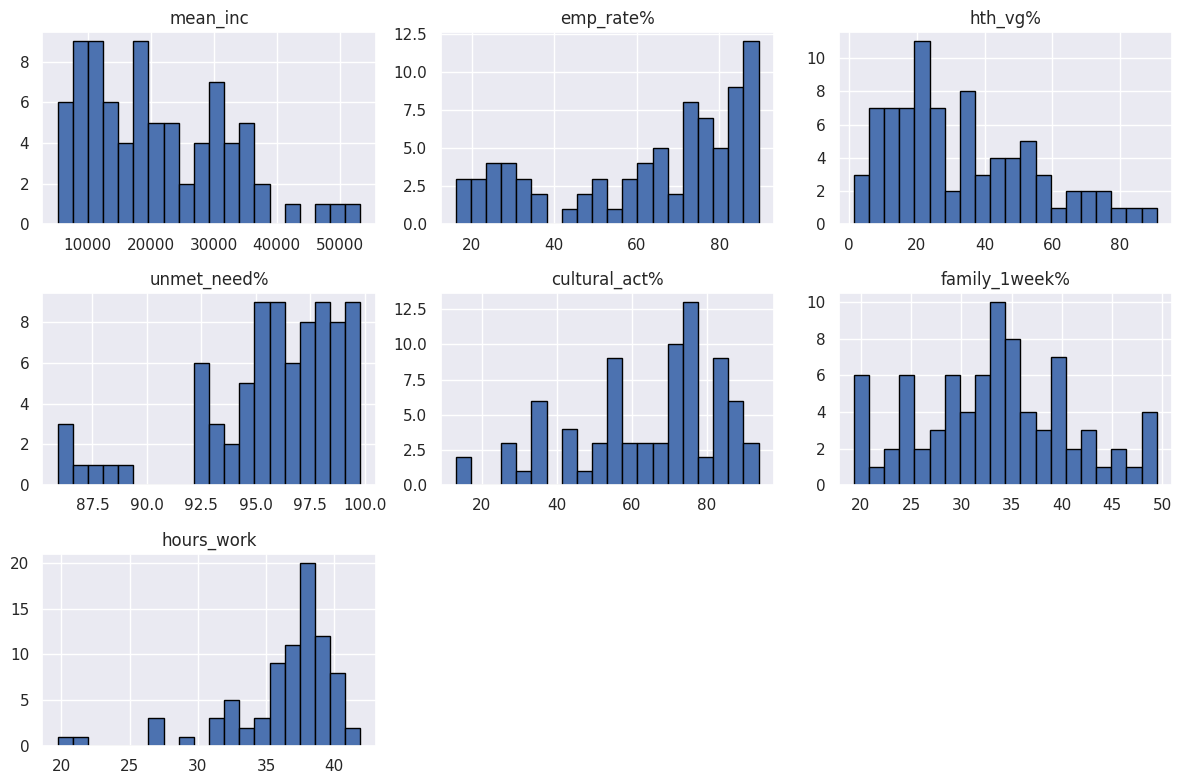

In [272]:
sns.set()
df_1[numeric_cols].hist(
    bins=20,
    figsize=(12,8),
    edgecolor = "black"
)

plt.tight_layout()
plt.show()


In [273]:
# Standardize the data

scaler = StandardScaler()
df_standardized = scaler.fit_transform(df_1[numeric_cols])

df_1_standardized = pd.DataFrame(df_standardized)
df_1_standardized.columns = numeric_cols
df_1_standardized.index = df_1.index

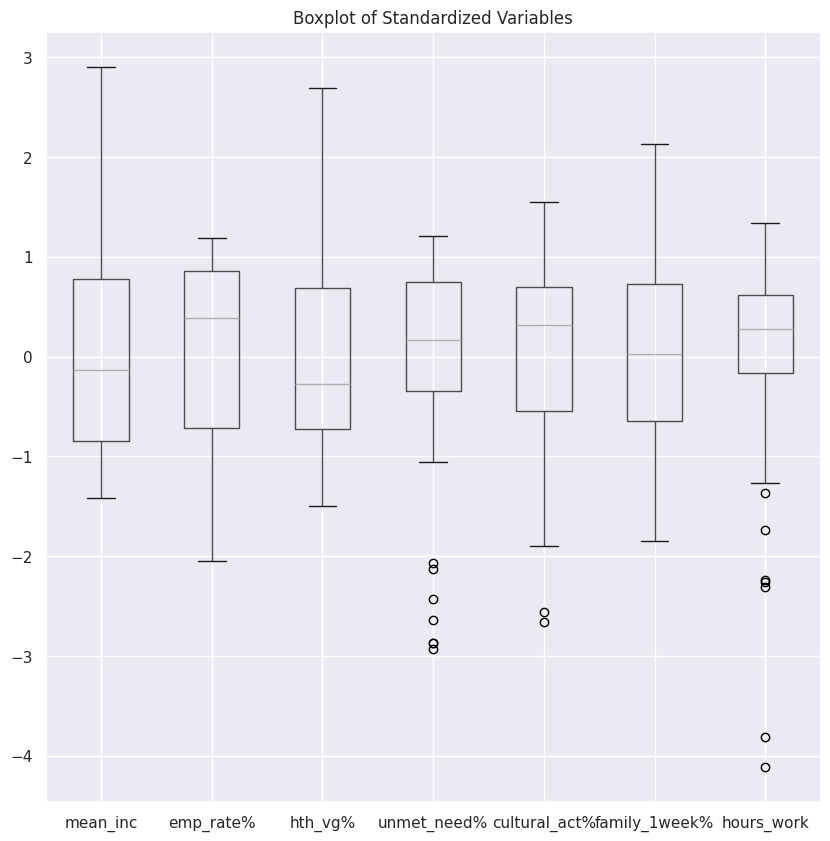

In [274]:
sns.set()
plt.figure(figsize=(10,10))
df_1_standardized[numeric_cols].boxplot()
plt.title('Boxplot of Standardized Variables')
plt.show()

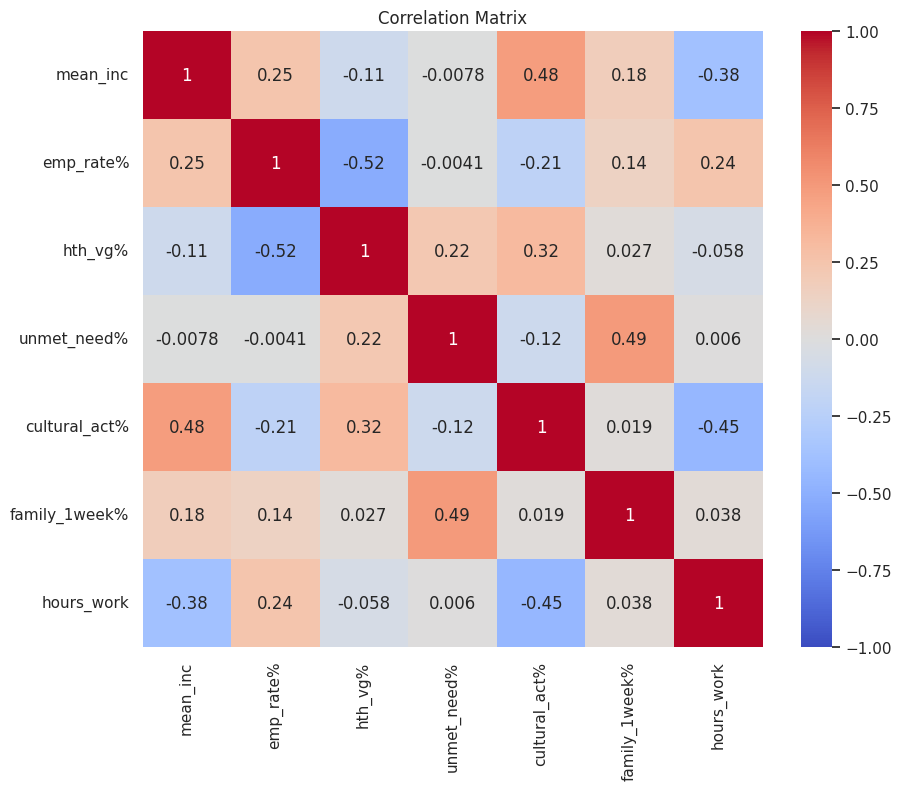

In [275]:
#Check correlations

corr_matrix = df_1_standardized.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

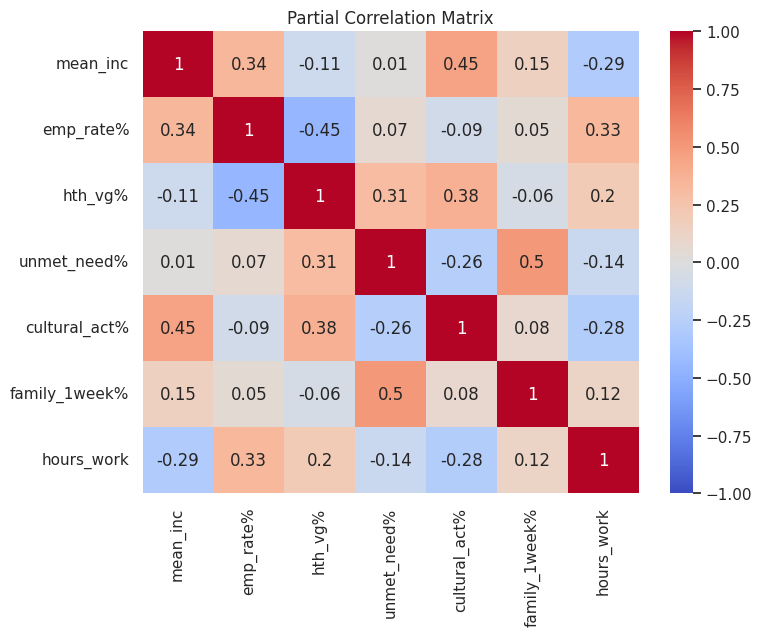

In [276]:
# Partial Correlation matrix

partial_corr_matrix = pd.DataFrame(index = numeric_cols, columns=numeric_cols)

for var1 in numeric_cols:
    for var2 in numeric_cols:
        if var1 == var2:
            partial_corr_matrix.loc[var1, var2] = 1.0
        else:
            covariates = [col for col in numeric_cols if col not in [var1, var2]]
            result = pg.partial_corr(data=df_1_standardized, x=var1, y=var2, covar=covariates)
            partial_corr_matrix.loc[var1, var2] = result['r'].values[0]

partial_corr_matrix = partial_corr_matrix.astype(float)

plt.figure(figsize=(8, 6))
sns.heatmap(partial_corr_matrix.round(2), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Partial Correlation Matrix')
plt.show()

In [277]:
#KMO
kmo_all, kmo_model = calculate_kmo(df_1_standardized)

#Overall KMO
print(f"Overall KMO: {kmo_model:.2f}")

#Individual KMO
kmo_all_series = pd.Series(kmo_all, index = numeric_cols)
print("\nIndividual KMO:")
print(kmo_all_series.round(2))

Overall KMO: 0.50

Individual KMO:
mean_inc         0.52
emp_rate%        0.51
hth_vg%          0.47
unmet_need%      0.41
cultural_act%    0.54
family_1week%    0.50
hours_work       0.55
dtype: float64


#Factor Analysis




In [278]:
#Initialize Factor Analysis

fa = FactorAnalyzer(n_factors=9, rotation = None)
#we indicate the number of variables we're going to use, we start with none to then analyse the other possible outcomes
fa.fit(df_1_standardized)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(n_factors=9, rotation=None, rotation_kwargs={})

In [283]:
#Kaiser Criterion

eigenvalues, _ = fa.get_eigenvalues()
print("Eigenvalues:\n", eigenvalues)
#eigenvalues must be higher than 1.


Eigenvalues:
 [2.00120825 1.63305775 1.55093571 0.70226969 0.49081956 0.33093834
 0.2907707 ]


In [284]:
#Pearson Criterion

variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(variance_ratio)
print("Cumulative variance explained:")
print(cumulative_variance)
#retain 80% of variance


Cumulative variance explained:
[0.28588689 0.51918086 0.7407431  0.84106734 0.91118442 0.95846133
 1.        ]


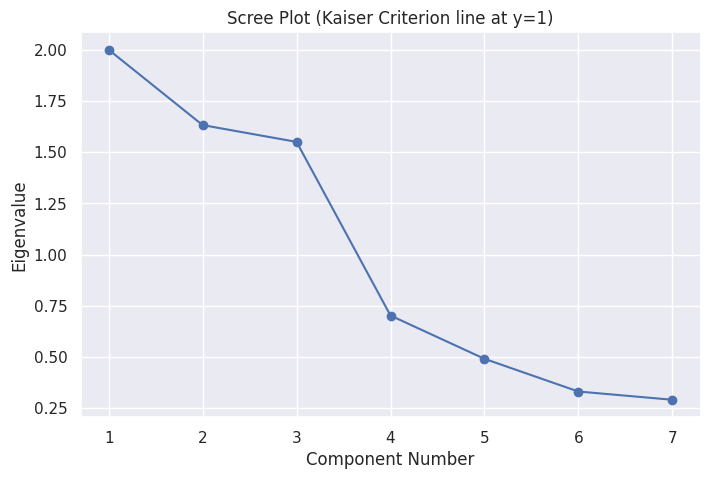

In [285]:
#Scree Plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o')
plt.title('Scree Plot (Kaiser Criterion line at y=1)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()
#elbow -1
#keep 3

In [286]:
#Perform FA with the number of factors you want to retain

n_factors = 3
fa = FactorAnalyzer(n_factors, rotation = None, method = "principal")
fa.fit(df_1_standardized)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(method='principal', rotation=None, rotation_kwargs={})

In [287]:
#Loadings
loadings = fa.loadings_

loadings_df = pd.DataFrame(loadings, index = numeric_cols, columns = ["F1","F2","F3"])
loadings_df

,F1,F2,F3
mean_inc,0.509571,0.737117,-0.013593
emp_rate%,-0.495022,0.728883,0.004597
hth_vg%,0.515346,-0.618521,0.309965
unmet_need%,0.024411,-0.013723,0.877666
cultural_act%,0.840151,0.168560,-0.118651
family_1week%,0.037418,0.322354,0.806356
hours_work,-0.723235,-0.208244,0.141655


In [288]:
#Communalities

communalities = fa.get_communalities()
print("Communalities:\n", communalities)
#we need communalities higher than 0,5

Communalities:
 [0.80318824 0.77633864 0.74422733 0.77108185 0.74834429 0.75552149
 0.58649988]


In [290]:
#RMSR

reconstructed_corr = np.dot(loadings, loadings.T)

residuals = corr_matrix.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)

rmsr = np.sqrt(np.mean(residuals[mask]**2))

#root mean square residual, we want it to be lower than 0.08. This test says it's 0.0962 which isn't good.

print(f"RMSR: {rmsr:.4f}")


RMSR: 0.1009


In [291]:
print("eigenvalues:", eigenvalues)
print("cumulative_variance:", cumulative_variance)
print("communalities:", communalities)
print("rmsr:", rmsr.round(5))

eigenvalues: [2.00120825 1.63305775 1.55093571 0.70226969 0.49081956 0.33093834
 0.2907707 ]
cumulative_variance: [0.28588689 0.51918086 0.7407431  0.84106734 0.91118442 0.95846133
 1.        ]
communalities: [0.80318824 0.77633864 0.74422733 0.77108185 0.74834429 0.75552149
 0.58649988]
rmsr: 0.10089


In [293]:
#Varimax Rotation

rotator = Rotator(method = "varimax")
rotated_loadings = rotator.fit_transform(loadings)

rotated_df = pd.DataFrame(rotated_loadings, index = numeric_cols, columns = ["F1","F2","F3"])

print("Rotated Loadings (Varimax):")
rotated_df

# mean_inc F1
# emp_rate F1
# hth_vg F3
# unmet_need F2
# cultural_act F1
# family_1week F2
# voluntary_act F1
# trust F3
# hours_work F1

# F1 -> Life in society (work and social)
# F2 -> Health and family
# F3 -> Trust and perceived health -> Perceived life

Rotated Loadings (Varimax):


,F1,F2,F3
mean_inc,0.802278,0.367469,0.156542
emp_rate%,-0.069046,0.867517,0.137788
hth_vg%,0.098512,-0.834962,0.193292
unmet_need%,-0.103451,-0.165039,0.856237
cultural_act%,0.821921,-0.264722,-0.052090
family_1week%,0.082256,0.124296,0.856333
hours_work,-0.743831,0.168086,0.070447


In [294]:
#Quartimax Rotation

rotator = Rotator(method = "quartimax")
rotated_loadings_quartimax = rotator.fit_transform(loadings)

rotated_quartimax_df = pd.DataFrame(rotated_loadings_quartimax, index = numeric_cols, columns = ["F1","F2","F3"])

print("Rotated Loadings (Quartimax):")
rotated_quartimax_df

Rotated Loadings (Quartimax):


,F1,F2,F3
mean_inc,0.820564,0.333074,0.137569
emp_rate%,-0.028307,0.870657,0.132264
hth_vg%,0.065882,-0.837093,0.197893
unmet_need%,-0.093150,-0.154319,0.859413
cultural_act%,0.808357,-0.300823,-0.066400
family_1week%,0.104972,0.126600,0.853507
hours_work,-0.734202,0.200992,0.083958
